# Chapitre 9 - Cours 2 : Optimiser le modèle et contourner le goulot autorégressif

Le cours 1 a montré que le decode est limité par la lecture des poids, un token à la fois.
Deux familles de remèdes agissent **sur le modèle** lui-même : le rendre plus petit
(compression) et produire plusieurs tokens par lecture des poids (décodage spéculatif et
ses cousins). Ce notebook couvre, dans la section *Inference Optimization* du livre :

- l'introduction (*model, hardware, service*) et *Model Optimization* ;
- *Model compression* : quantification, distillation, élagage (*pruning*) ;
- *Overcoming the autoregressive decoding bottleneck* : *Speculative decoding*,
  *Inference with reference*, *Parallel decoding*.

**Plan.** 1. Trois niveaux d'optimisation ; 2. Quantification : poids seuls ou poids et
activations ; 3. Quantification mesurée : mémoire, vitesse, perplexité ; 4. Distillation ;
5. Élagage ; 6. Le goulot autorégressif ; 7. Décodage spéculatif ; 8. Inférence avec
référence ; 9. Décodage parallèle ; Synthèse.

In [1]:
import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)


def release(*objs):
    """Libère des modèles chargés hors du cache de llm.load."""
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()

## 1. Trois niveaux d'optimisation (section *Inference Optimization*)

Le livre file la métaphore du tir à l'arc : optimiser le **modèle**, c'est fabriquer de
meilleures flèches ; optimiser le **matériel**, entraîner un archer plus fort ; optimiser le
**service**, régler tout le dispositif (arc, conditions de tir, ordre de passage). En
production on combine les trois. Les techniques au niveau du modèle peuvent **changer son
comportement** : la figure 9-8 du livre montre le même Llama obtenir des scores différents
selon le fournisseur qui le sert. Les techniques de service, elles, ne doivent pas changer
les sorties.

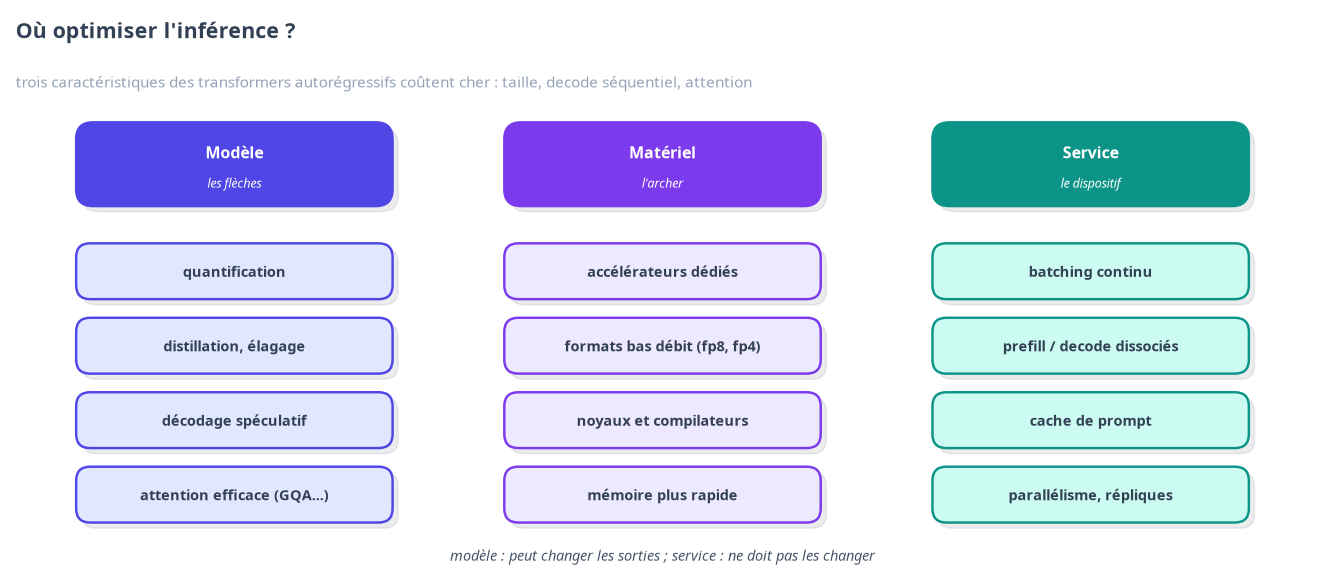

In [2]:
d = Diagram(14, 5.0, title="Où optimiser l'inférence ?",
            subtitle="trois caractéristiques des transformers autorégressifs coûtent cher : taille, decode séquentiel, attention")
cols = [("Modèle", "les flèches", INDIGO, ["quantification", "distillation, élagage", "décodage spéculatif",
                                           "attention efficace (GQA...)"]),
        ("Matériel", "l'archer", VIOLET, ["accélérateurs dédiés", "formats bas débit (fp8, fp4)",
                                         "noyaux et compilateurs", "mémoire plus rapide"]),
        ("Service", "le dispositif", TEAL, ["batching continu", "prefill / decode dissociés",
                                           "cache de prompt", "parallélisme, répliques"])]
for i, (t, sub, c, items) in enumerate(cols):
    x = 2.4 + i * 4.6
    d.box(f"h{i}", x, 4.3, t, sub=sub, color=c, filled=True, w=3.4, h=0.9)
    for j, it in enumerate(items):
        d.box(f"i{i}{j}", x, 3.15 - j * 0.8, it, color=c, w=3.4, h=0.6, fontsize=9.5)
d.note(7.0, 0.1, "modèle : peut changer les sorties ; service : ne doit pas les changer", fontsize=9.5)
d.show()

> **À retenir.** Taille du modèle, decode autorégressif et attention sont les trois sources
> du coût. Les optimisations « modèle » sont puissantes mais doivent être **évaluées**
> (chapitres 3 et 4) : elles peuvent dégrader la qualité.

## 2. Quantification : poids seuls ou poids et activations (section *Model compression*)

Le chapitre 7 a présenté la quantification ; ici, le point de vue est la **vitesse**. En
decode, chaque token impose de lire tous les poids : passer de 16 à 8 bits divise par deux
les octets lus, donc (idéalement) le temps d'un pas.

**Quantification symétrique « absmax ».** Pour $b$ bits, on choisit une échelle
$s = \max |w| / (2^{b-1} - 1)$ et on stocke l'entier $q = \mathrm{round}(w/s)$ ; on
reconstruit $\hat w = s\,q$. L'erreur d'arrondi est au plus $s/2$ : elle dépend du **plus
grand** coefficient couvert par l'échelle. D'où trois granularités : une échelle par
tenseur, par canal (ligne de la matrice), ou par **groupe** de $g$ poids consécutifs (au
prix de $16/g$ bits par poids pour stocker les échelles).

Deux familles :

- **poids seuls** (*weight-only*, de loin la plus répandue selon le livre) : on stocke les
  poids en int8 / int4 et on les déquantifie à la volée avant le calcul en bf16. Gain :
  mémoire et bande passante, donc decode ;
- **poids et activations** (W8A8...) : le produit lui-même est fait en entiers (ou en fp8),
  ce qui accélère aussi le **calcul**, donc le prefill. Mais les activations sont plus
  difficiles à quantifier.

Regardons pourquoi sur Qwen2.5-0.5B : poids d'une matrice MLP, et activations en entrée de
cette même matrice sur un vrai texte.

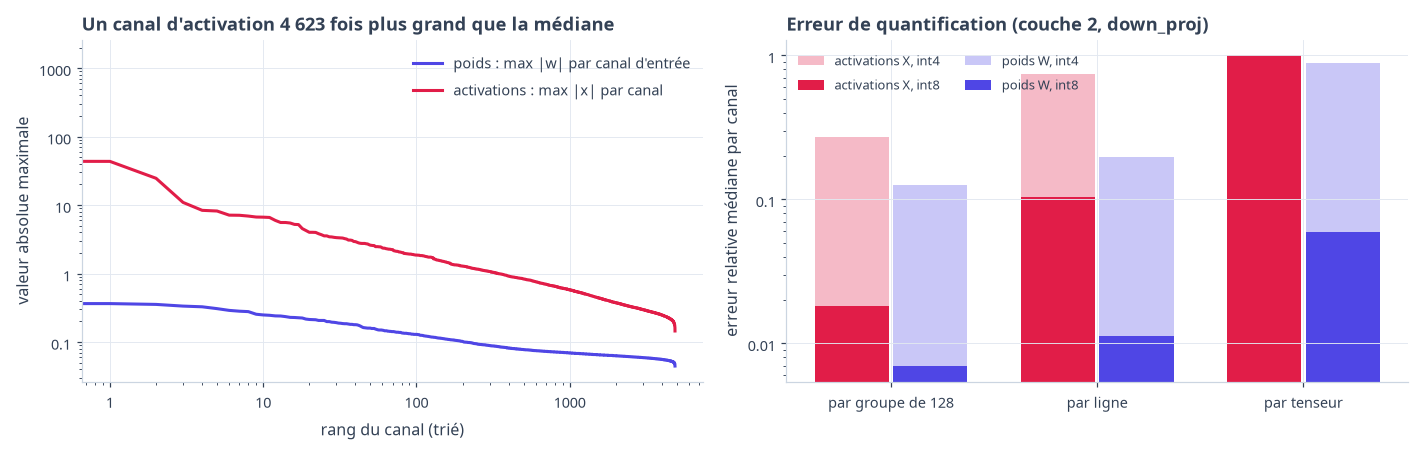

In [3]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)
layer = model.model.layers[2].mlp
acts = {}


def grab(module, inputs, output):
    acts["x"] = inputs[0][0].detach().float().cpu().numpy()  # un hook qui renvoie None ne modifie pas la sortie


h = layer.down_proj.register_forward_hook(grab)
with torch.no_grad():
    inf.retry_oom(model, tok(inf.CALIB_TEXT, return_tensors="pt")["input_ids"].cuda())
h.remove()
W = layer.down_proj.weight.detach().float().cpu().numpy()  # (896, 4864)
X = acts["x"]  # (tokens, 4864) : activations en entrée de down_proj, couche 2


def median_channel_err(a, q):
    """Erreur relative médiane par canal d'entrée (colonne) : ce que subit un canal typique."""
    return float(np.median(np.linalg.norm(a - q, axis=0) / np.maximum(np.linalg.norm(a, axis=0), 1e-12)))


rows = []
for label, arr in [("poids W", W), ("activations X", X)]:
    for gran, kw in [("par tenseur", dict(axis=None)), ("par ligne", dict(axis=1)),
                     ("par groupe de 128", dict(group_size=128))]:
        for bits in [8, 4]:
            q, _ = inf.quantize_symmetric(arr, bits, **kw)
            rows.append({"tenseur": label, "granularité": gran, "bits": bits, "erreur": median_channel_err(arr, q)})
err = pd.DataFrame(rows).pivot_table(index=["tenseur", "granularité"], columns="bits", values="erreur")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
mx_w, mx_x = np.abs(W).max(0), np.abs(X).max(0)
ax.plot(np.sort(mx_w)[::-1], color=INDIGO, label="poids : max |w| par canal d'entrée")
ax.plot(np.sort(mx_x)[::-1], color=ROSE, label="activations : max |x| par canal")
ax.set_yscale("log"); plain_log_axis(ax, "y"); ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlabel("rang du canal (trié)"); ax.set_ylabel("valeur absolue maximale")
ax.set_title(f"Un canal d'activation {mx_x.max() / np.median(mx_x):,.0f} fois plus grand que la médiane".replace(",", " "))
ax.legend()
ax = axes[1]
e8 = err[8].unstack(0); e4 = err[4].unstack(0)
xx = np.arange(len(e8))
for j, (col, c) in enumerate(zip(e8.columns, [ROSE, INDIGO])):
    ax.bar(xx + (j - 0.5) * 0.38, e4[col], 0.36, color=c, alpha=0.3, label=f"{col}, int4")
    ax.bar(xx + (j - 0.5) * 0.38, e8[col], 0.36, color=c, label=f"{col}, int8")
ax.set_xticks(xx, e8.index); ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_ylabel("erreur relative médiane par canal"); ax.set_title("Erreur de quantification (couche 2, down_proj)")
ax.legend(fontsize=8.5, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()
err.style.format("{:.4f}")

Les poids sont « sages » : leur maximum varie peu d'un canal à l'autre, et l'erreur int8
reste faible même avec une seule échelle. Les activations, elles, ont quelques **canaux
aberrants** (ici un canal dépasse la médiane de plusieurs ordres de grandeur, phénomène
connu sous le nom de *massive activations*) : avec une échelle par tenseur, ce canal fixe
le pas de la grille et la plupart des autres valeurs sont arrondies à zéro (erreur proche
de 100 % pour un canal typique). Une échelle **par token** (par ligne) aide en 8 bits mais
reste très insuffisante en 4 bits, car le canal aberrant est présent dans tous les tokens ;
il faut descendre au groupe.
C'est l'observation à l'origine de LLM.int8() (Dettmers et al., 2022), qui garde ces
canaux en 16 bits, et de SmoothQuant, qui transfère la difficulté des activations vers les
poids.

> **À retenir.** L'erreur d'arrondi est proportionnelle à l'échelle, donc au plus grand
> coefficient du groupe. Les poids se quantifient bien ; les activations, à cause de leurs
> canaux aberrants, demandent des schémas plus fins : c'est pourquoi la quantification des
> poids seuls domine en pratique.

## 3. Quantification mesurée : mémoire, vitesse, perplexité (section *Model compression*)

**Qualité selon le nombre de bits.** On simule la quantification des poids seuls (on
remplace chaque matrice par sa version quantifiée puis déquantifiée, en arrondi au plus
proche, sans aucune calibration) et on mesure la perplexité de Qwen2.5-0.5B sur un texte
d'évaluation (rédigé pour ce dépôt, environ 230 tokens).

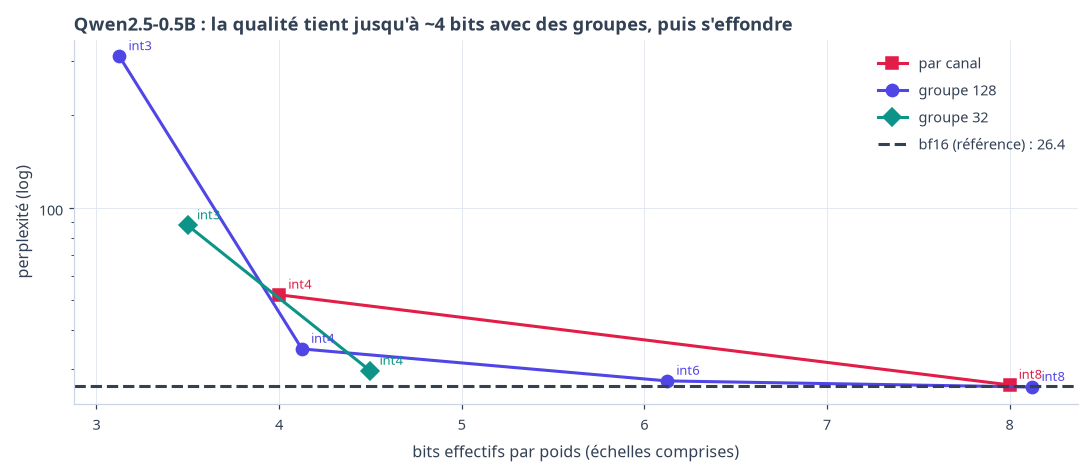

schéma,bits effectifs / poids,perplexité
int8 par canal,8.00,26.6
int8 groupe 128,8.12,26.2
int6 groupe 128,6.12,27.4
int4 par canal,4.00,52.2
int4 groupe 128,4.12,34.8
int4 groupe 32,4.50,29.5
int3 groupe 128,3.12,310.2
int3 groupe 32,3.50,87.6


In [4]:
state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}  # copie sur CPU
ppl_ref = inf.retry_oom(inf.perplexity_of, model, tok, inf.EVAL_TEXT)
configs = [(8, None), (8, 128), (6, 128), (4, None), (4, 128), (4, 32), (3, 128), (3, 32)]
rows = []


def ppl_fake_quant(bits, g):
    model.load_state_dict(state)
    inf.fake_quantize_model_(model, bits, g)
    return inf.perplexity_of(model, tok, inf.EVAL_TEXT)


for bits, g in configs:
    rows.append({"schéma": f"int{bits} " + (f"groupe {g}" if g else "par canal"), "bits": bits, "groupe": g,
                 "bits effectifs / poids": inf.quant_bits_per_weight(bits, g),
                 "perplexité": inf.retry_oom(ppl_fake_quant, bits, g)})
model.load_state_dict(state)
fq = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.4))
for gname, c, mk in [("par canal", ROSE, "s"), ("groupe 128", INDIGO, "o"), ("groupe 32", TEAL, "D")]:
    sub = fq[fq["schéma"].str.contains(gname)]
    ax.plot(sub["bits effectifs / poids"], sub["perplexité"], mk + "-", color=c, label=gname, ms=8)
    for _, r in sub.iterrows():
        ax.annotate(r["schéma"].split()[0], (r["bits effectifs / poids"], r["perplexité"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=8.5, color=c)
ax.axhline(ppl_ref, color=SLATE, ls="--", label=f"bf16 (référence) : {ppl_ref:.1f}")
ax.set_yscale("log"); plain_log_axis(ax, "y", fmt=lambda v: f"{v:.0f}")
ax.set_xlabel("bits effectifs par poids (échelles comprises)"); ax.set_ylabel("perplexité (log)")
ax.set_title("Qwen2.5-0.5B : la qualité tient jusqu'à ~4 bits avec des groupes, puis s'effondre")
ax.legend()
plt.tight_layout(); plt.show()
fq[["schéma", "bits effectifs / poids", "perplexité"]].style.format(
    {"bits effectifs / poids": "{:.2f}", "perplexité": "{:.1f}"}).hide(axis="index")

En 8 bits, la perplexité ne bouge pratiquement pas. En 4 bits, une échelle par canal
dégrade déjà nettement le modèle, alors que des groupes de 128 ou 32 poids limitent la
casse pour un surcoût de 0,1 à 0,5 bit par poids. En 3 bits, même les groupes ne suffisent
plus avec un simple arrondi : il faut des méthodes calibrées (GPTQ, AWQ) qui choisissent
l'arrondi pour minimiser l'erreur sur les sorties. Notez qu'un modèle de 0,5 milliard de
paramètres est **plus fragile** qu'un gros modèle : chaque poids y porte plus
d'information.

**Mesures réelles avec bitsandbytes.** On charge Qwen2.5-1.5B en bf16, en int8 (LLM.int8 :
poids **et** activations en int8, canaux aberrants en 16 bits) et en nf4 (4 bits, poids
seuls, calcul en bf16). Pour chaque variante : empreinte mémoire, débit de decode (32
tokens, médiane de 3), durée d'un prefill de 512 tokens, perplexité.

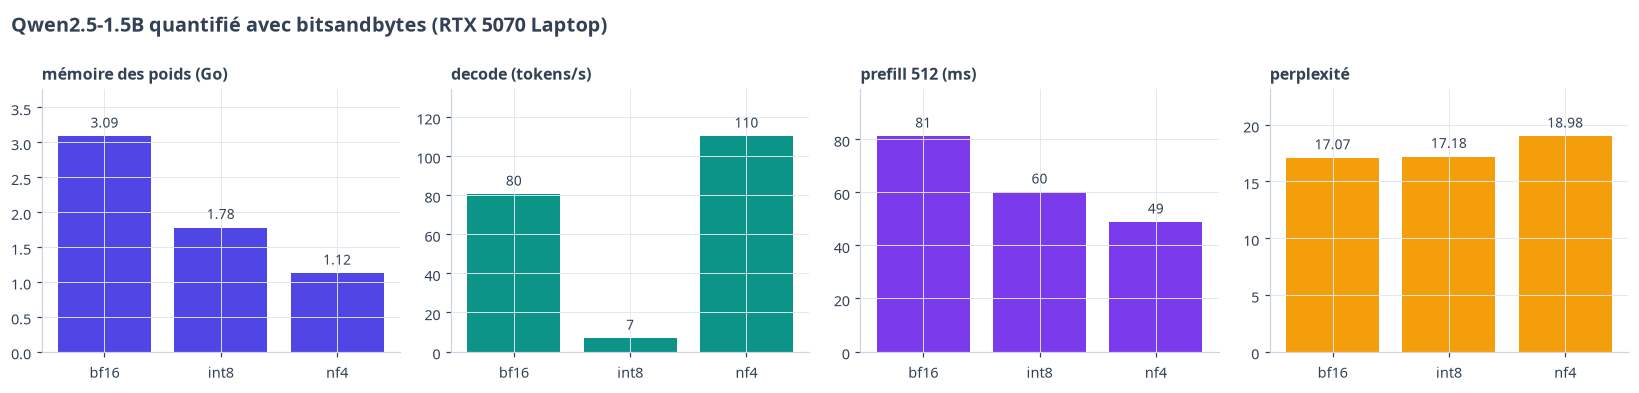

In [5]:
del layer, state
llm.free_gpu(); release(model)
del model


def measure_variant(qt):
    torch.cuda.reset_peak_memory_stats()
    tk, mdl = inf.load_model(llm.MEDIUM, qt)
    ids = tk("The history of computing began", return_tensors="pt")["input_ids"][0].tolist()
    dec = inf.time_fn(lambda: inf.greedy_generate(mdl, ids, 32), repeats=3, warmup=1)
    x = inf.random_ids(1, 512)
    with torch.no_grad():
        pre = inf.time_fn(lambda: mdl(x, logits_to_keep=1), repeats=5, warmup=1)
    out = {"variante": qt, "mémoire des poids (Go)": mdl.get_memory_footprint() / 1e9,
           "decode (tokens/s)": 32 / dec["median"], "prefill 512 (ms)": pre["median"] * 1e3,
           "perplexité": inf.perplexity_of(mdl, tk, inf.EVAL_TEXT)}
    release(mdl)
    return out


bnb = pd.DataFrame([inf.retry_oom(measure_variant, qt) for qt in ["bf16", "int8", "nf4"]]).set_index("variante")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col, c in zip(axes, bnb.columns, [INDIGO, TEAL, VIOLET, AMBER]):
    ax.bar(bnb.index, bnb[col], color=c)
    annotate_bars(ax, "{:.2f}" if bnb[col].max() < 30 else "{:.0f}")
    ax.set_title(col, fontsize=10.5); ax.set_ylim(0, bnb[col].max() * 1.22)
finish(fig, "Qwen2.5-1.5B quantifié avec bitsandbytes (RTX 5070 Laptop)")
plt.show()

Ce que montrent les mesures (les valeurs exactes varient d'une exécution à l'autre, les
rapports sont stables) :

- **mémoire** : int8 et nf4 divisent bien l'empreinte (environ 1,7x et 2,7x ; pas 2x et
  4x, car la table des plongements, partagée avec la tête de sortie, reste en bf16) ;
- **perplexité** : int8 est presque indiscernable du bf16, nf4 un peu au-dessus ;
- **vitesse** : c'est la surprise pédagogique. LLM.int8 est **plus lent** que le bf16 en
  decode comme en prefill : la décomposition des canaux aberrants et les conversions
  coûtent plus que l'économie de bande passante, sur un petit modèle. Le nf4 accélère en
  général le decode (moins d'octets à lire), mais ralentit le prefill, où la
  déquantification à la volée s'ajoute à un calcul déjà limité par les FLOPs.

Leçon : une quantification n'accélère que si un **noyau** efficace l'exploite (cf. cours 3).
Les moteurs de service (vLLM, TensorRT-LLM, llama.cpp) utilisent des noyaux int4 / fp8
dédiés (Marlin, AWQ, fp8 natif des tensor cores) qui, eux, tiennent la promesse : l'étude
de cas PyTorch du livre (figure 9-14) gagne nettement en débit en passant les poids de
Llama-7B en int8 puis int4.

> **À retenir.** Quantifier les poids réduit sûrement la mémoire, presque toujours sans
> perte en 8 bits, avec une perte modérée en 4 bits par groupes. Le gain de vitesse, lui,
> dépend du noyau : **mesurez** sur votre matériel avant de conclure.

## 4. Distillation (section *Model compression*)

La **distillation** (chapitre 8) entraîne un petit modèle, l'**élève**, à imiter un grand,
le **professeur**. On minimise typiquement la divergence de Kullback-Leibler entre les
distributions du prochain token, adoucies par une température $\tau$ :
$$\mathcal{L} = \tau^2 \, \mathrm{KL}\big(p_{\text{prof}}^{(\tau)} \,\|\, p_{\text{élève}}^{(\tau)}\big),
\qquad p^{(\tau)} = \mathrm{softmax}(z/\tau).$$
L'élève apprend non seulement la bonne réponse mais aussi la **forme** de la distribution
du professeur (quels autres tokens sont plausibles) : c'est le « savoir sombre » de Hinton
et al. (2015), d'autant plus visible que $\tau$ est grand.

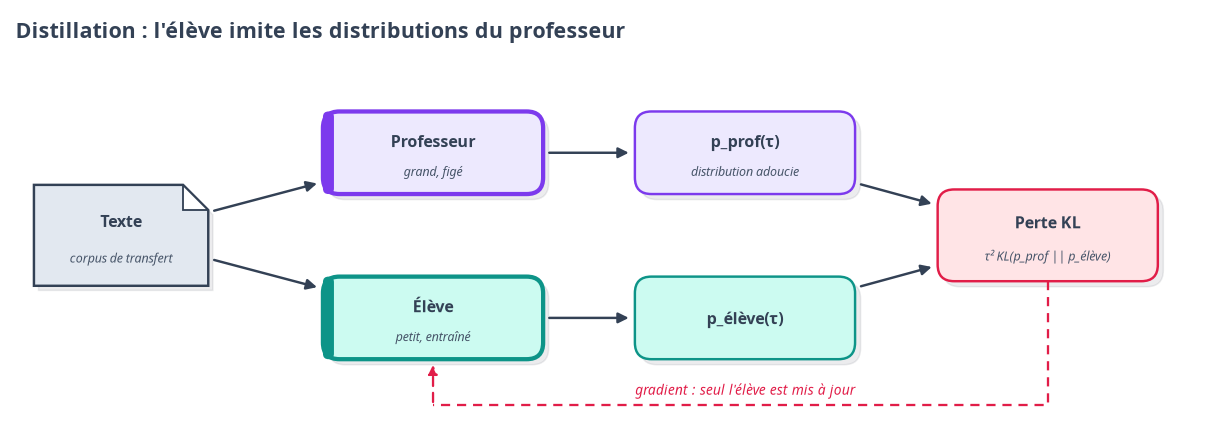

In [6]:
d = Diagram(13, 4.0, title="Distillation : l'élève imite les distributions du professeur")
d.box("x", 1.2, 2.1, "Texte", sub="corpus de transfert", color=SLATE, kind="doc", w=1.9, h=1.1)
d.box("t", 4.6, 3.0, "Professeur", sub="grand, figé", color=VIOLET, kind="model", w=2.4)
d.box("s", 4.6, 1.2, "Élève", sub="petit, entraîné", color=TEAL, kind="model", w=2.4)
d.box("pt", 8.0, 3.0, "p_prof(τ)", sub="distribution adoucie", color=VIOLET, w=2.4)
d.box("ps", 8.0, 1.2, "p_élève(τ)", color=TEAL, w=2.4)
d.box("kl", 11.3, 2.1, "Perte KL", sub="τ² KL(p_prof || p_élève)", color=ROSE, w=2.4, h=1.0)
d.arrow("x", "t"); d.arrow("x", "s"); d.arrow("t", "pt"); d.arrow("s", "ps")
d.arrow("pt", "kl"); d.arrow("ps", "kl")
d.line([(11.3, 1.6), (11.3, 0.25), (4.6, 0.25), (4.6, 0.72)], color=ROSE, style="dashed", lw=1.5)
d.note(8.0, 0.42, "gradient : seul l'élève est mis à jour", color=ROSE, fontsize=9)
d.show()

Pas d'entraînement ici (le chapitre 8 en traite), mais une mesure utile pour la suite :
**à quel point un petit modèle imite-t-il déjà un grand ?** Qwen2.5-0.5B et Qwen2.5-1.5B
partagent tokenizer et données d'entraînement, et le petit a été en partie distillé du
grand. Sur le texte d'évaluation, on compare token par token leurs distributions.

accord top-1 (même token le plus probable) : 65% ; KL(prof || élève) moyenne : 0.45 nats


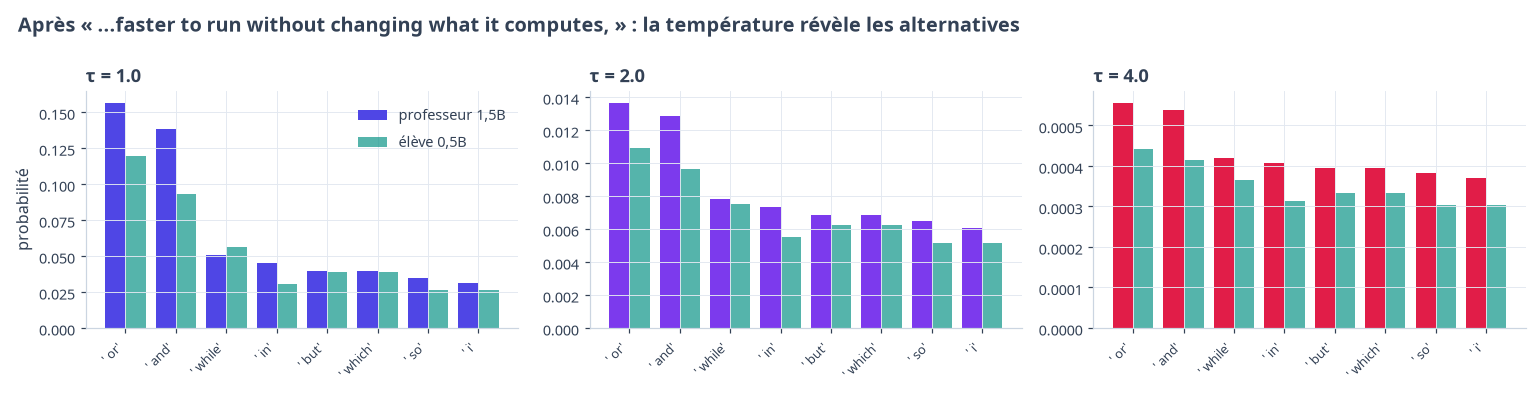

In [7]:
tok_t, tgt = inf.retry_oom(llm.load, llm.MEDIUM)
tok_d, drf = inf.retry_oom(llm.load, llm.SMALL)
ids = tok_t(inf.EVAL_TEXT, return_tensors="pt")["input_ids"].cuda()


def both_logits():
    with torch.no_grad():  # logits rapatriés sur CPU pour libérer la mémoire GPU
        return tgt(ids).logits[0].float().cpu(), drf(ids).logits[0].float().cpu()


zt, zs = inf.retry_oom(both_logits)
agree = (zt.argmax(-1) == zs.argmax(-1)).float().mean().item()
kl = torch.nn.functional.kl_div(torch.log_softmax(zs, -1), torch.log_softmax(zt, -1), log_target=True,
                                reduction="none").sum(-1)
print(f"accord top-1 (même token le plus probable) : {agree:.0%} ; KL(prof || élève) moyenne : {kl.mean():.2f} nats")

hesite = (zt.softmax(-1).max(-1).values < 0.6) & (torch.arange(len(zt)) >= 20)
pos = int(torch.argmax(hesite.float()))  # une position (après le début) où le professeur hésite
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
top = torch.topk(zt[pos], 8).indices
labels = [repr(tok_t.decode([i])) for i in top.tolist()]
for ax, tau, c in zip(axes, [1.0, 2.0, 4.0], [INDIGO, VIOLET, ROSE]):
    pt = llm.softmax(zt[pos].cpu().numpy(), tau)[top.cpu().numpy()]
    ps = llm.softmax(zs[pos].cpu().numpy(), tau)[top.cpu().numpy()]
    xx = np.arange(8)
    ax.bar(xx - 0.2, pt, 0.4, color=c, label="professeur 1,5B")
    ax.bar(xx + 0.2, ps, 0.4, color=TEAL, alpha=0.7, label="élève 0,5B")
    ax.set_xticks(xx, labels, rotation=45, ha="right", fontsize=8.5); ax.set_title(f"τ = {tau}")
axes[0].set_ylabel("probabilité"); axes[0].legend()
context = tok_t.decode(ids[0, max(0, pos - 8):pos + 1].tolist())
finish(fig, f"Après « ...{context.strip()} » : la température révèle les alternatives")
plt.show()

Le petit modèle choisit le même token que le grand dans une majorité des positions (de
l'ordre de deux sur trois sur ce texte rédigé par un humain ; davantage sur un texte
généré par le grand modèle lui-même, plus prévisible) : c'est précisément ce qui rendra
le **décodage spéculatif** efficace (section 7). La
température $\tau > 1$ aplatit les distributions et fait apparaître les alternatives que
l'élève doit aussi apprendre à classer.

> **À retenir.** La distillation transfère le comportement d'un grand modèle dans un petit,
> souvent à qualité comparable pour une tâche donnée. Un bon élève est aussi un bon
> **brouillon** pour le décodage spéculatif.

## 5. Élagage (section *Model compression*)

Si un petit modèle peut imiter un grand, peut-être existe-t-il **dans** le grand modèle un
sous-ensemble de paramètres suffisant : c'est l'idée de l'**élagage** (*pruning*), et de
l'hypothèse du « ticket gagnant » (Frankle et Carbin, 2019). Deux sens :

- **non structuré** : mettre à zéro des poids individuels (le modèle devient creux, sa
  taille ne change pas tant qu'on ne stocke pas le format creux) ;
- **structuré** : supprimer des neurones, des têtes ou des couches entières (l'architecture
  rétrécit vraiment, d'où un gain de vitesse direct).

Testons sur les MLP de Qwen2.5-0.5B (environ 60 % des paramètres hors plongements), sans
réentraînement. Trois critères non structurés : valeur absolue $|w|$, critère *Wanda*
$|w| \cdot \|x\|$ (Sun et al., 2023, qui tient compte de la norme de l'activation d'entrée,
mesurée sur un texte de **calibration** distinct du texte d'évaluation) et hasard.

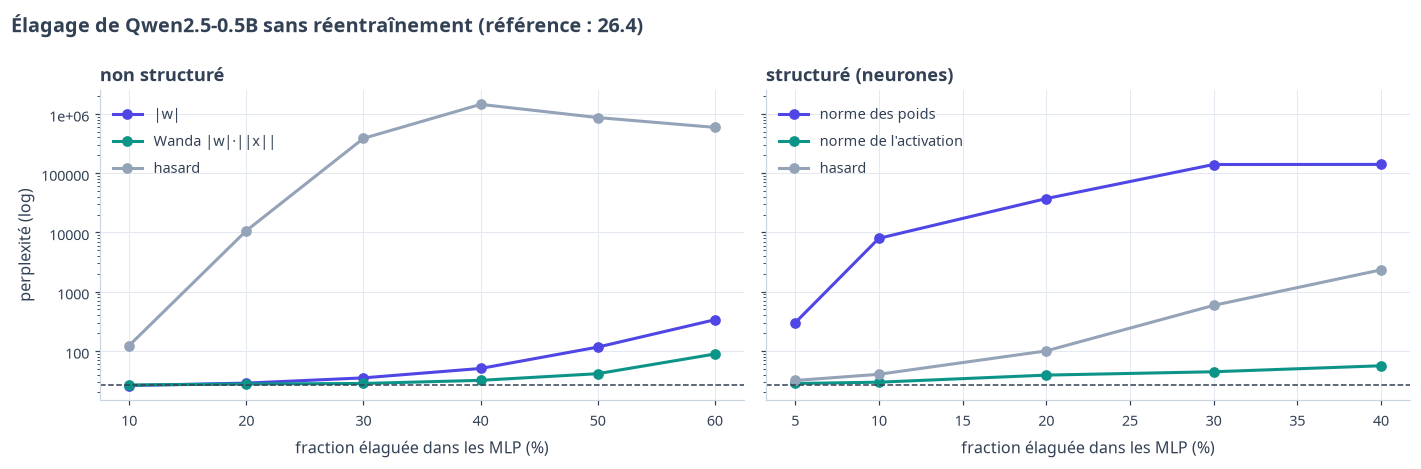

In [8]:
model = drf
state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}  # copie sur CPU
norms = inf.retry_oom(inf.linear_input_norms, model, tok_d, inf.CALIB_TEXT, scope="mlp")
ppl0 = inf.retry_oom(inf.perplexity_of, model, tok_d, inf.EVAL_TEXT)


def ppl_after(fn, *args, **kw):
    model.load_state_dict(state)
    fn(model, *args, **kw)
    return inf.perplexity_of(model, tok_d, inf.EVAL_TEXT)


rows = []
for sp in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    for meth in ["magnitude", "wanda", "random"]:
        p_ = inf.retry_oom(ppl_after, inf.magnitude_prune_, sp, method=meth, input_norms=norms)
        rows.append(dict(type="non structuré", critère=meth, fraction=sp, ppl=p_))
for fr in [0.05, 0.1, 0.2, 0.3, 0.4]:
    for meth in ["weights", "activation", "random"]:
        p_ = inf.retry_oom(ppl_after, inf.structured_prune_mlp_, fr, method=meth, input_norms=norms)
        rows.append(dict(type="structuré (neurones)", critère=meth, fraction=fr, ppl=p_))
model.load_state_dict(state)
pr = pd.DataFrame(rows)
names = {"magnitude": "|w|", "wanda": "Wanda |w|·||x||", "random": "hasard", "weights": "norme des poids",
         "activation": "norme de l'activation"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, typ in zip(axes, ["non structuré", "structuré (neurones)"]):
    sub = pr[pr["type"] == typ]
    for (meth, g), c in zip(sub.groupby("critère", sort=False), [INDIGO, TEAL, GRAY]):
        ax.plot(g["fraction"] * 100, g["ppl"], "o-", color=c, label=names[meth])
    ax.axhline(ppl0, color=SLATE, ls="--", lw=1)
    ax.set_yscale("log"); plain_log_axis(ax, "y", fmt=lambda v: f"{v:g}")
    ax.set_xlabel("fraction élaguée dans les MLP (%)"); ax.set_title(typ); ax.legend()
axes[0].set_ylabel("perplexité (log)")
finish(fig, f"Élagage de Qwen2.5-0.5B sans réentraînement (référence : {ppl0:.1f})")
plt.show()

Trois enseignements :

- l'élagage **non structuré** par valeur absolue tolère environ 20 à 30 % de zéros avec une
  dégradation modérée ; Wanda, qui pondère par l'activation, fait mieux à fort taux ; le
  hasard est catastrophique dès 10 % : le **critère** compte autant que le taux ;
- l'élagage **structuré** est beaucoup plus brutal. Pire, le critère « naturel » (norme des
  poids) fait **moins bien que le hasard** : certains neurones ont des poids de faible norme
  mais des activations énormes, et les supprimer détruit le modèle. Le critère fondé sur
  les activations mesurées tient bien mieux. Encore les canaux aberrants !
- dans tous les cas, un **réentraînement** (finetuning) après élagage récupère une partie
  de la qualité, ce que le livre mentionne.

**Pourquoi l'élagage reste rare en pratique** (selon le livre) : il demande de comprendre
l'architecture, et des zéros dispersés n'accélèrent rien sans matériel ou noyaux qui
exploitent la parcimonie. Le compromis le plus répandu est la parcimonie **semi-structurée
2:4** des GPU NVIDIA : dans chaque groupe de 4 poids, 2 sont nuls, et les tensor cores
sautent les zéros (d'où les chiffres « avec parcimonie » des fiches, deux fois plus élevés).

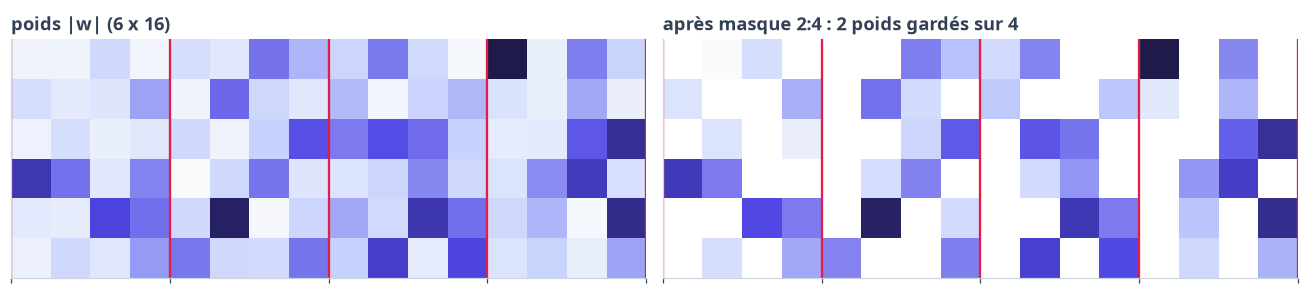

fraction gardée : 0.5


In [9]:
w_demo = rng.normal(size=(6, 16))
mask = inf.two_four_mask(w_demo)
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6))
axes[0].imshow(np.abs(w_demo), cmap="aie_seq"); axes[0].set_title("poids |w| (6 x 16)")
axes[1].imshow(np.where(mask, np.abs(w_demo), np.nan), cmap="aie_seq")
axes[1].set_title("après masque 2:4 : 2 poids gardés sur 4")
for ax in axes:
    ax.set_xticks(np.arange(-0.5, 16, 4), minor=False, labels=[]); ax.set_yticks([]); ax.grid(color=ROSE, lw=1.5, axis="x")
plt.tight_layout(); plt.show()
print("fraction gardée :", mask.mean())

> **À retenir.** Élaguer, c'est supprimer les paramètres les moins utiles ; le critère doit
> tenir compte des activations, et le gain de vitesse exige une parcimonie que le matériel
> sait exploiter (structurée ou 2:4). Quantification et distillation restent les leviers de
> compression les plus utilisés.

## 6. Le goulot autorégressif (section *Overcoming the autoregressive decoding bottleneck*)

Générer 100 tokens à 100 ms le token prend 10 s, quoi qu'on fasse du prefill. Le livre
rappelle qu'un token de sortie coûte 2 à 4 fois plus cher qu'un token d'entrée chez les
fournisseurs d'API, et qu'il a sur la latence l'impact d'environ 100 tokens d'entrée.
Pourquoi ? Parce que chaque pas de decode relit **tous** les poids pour **un** token (cours
1, section 3), et laisse donc l'essentiel du calcul inutilisé. L'idée commune des trois
techniques qui suivent : **proposer plusieurs tokens à l'avance**, puis les faire
**vérifier en une seule passe** par le modèle, qui a justement du calcul à revendre.

Vérifions qu'une passe sur $k + 1$ tokens coûte à peine plus qu'une passe sur un seul,
avec Qwen2.5-1.5B et un cache KV de 128 tokens.

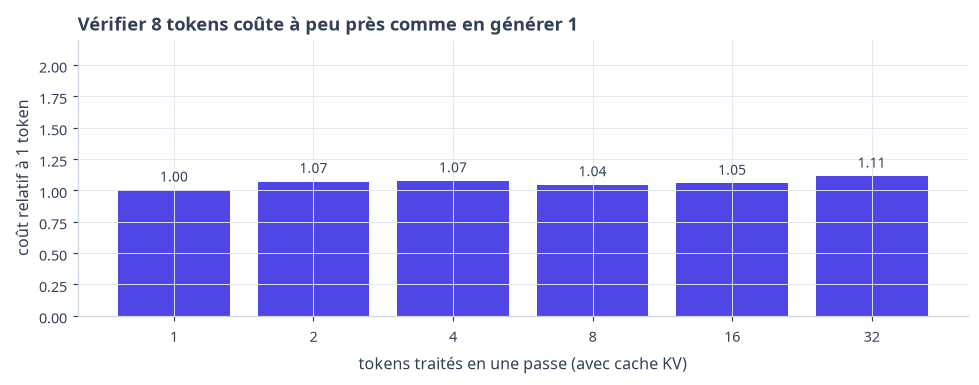

In [10]:
def verify_cost():
    res = []
    x = inf.random_ids(1, 128)
    with torch.no_grad():
        for k1 in [1, 2, 4, 8, 16, 32]:
            def step():
                c = tgt(x, use_cache=True, logits_to_keep=1).past_key_values
                return c
            c = step()
            y = inf.random_ids(1, k1, seed=1)

            def fwd():
                o = tgt(y, cache=c, use_cache=True, logits_to_keep=k1)
                inf._crop_to(c, 128)
            res.append(dict(tokens=k1, ms=inf.time_fn(fwd, repeats=15, warmup=3)["median"] * 1e3))
    return pd.DataFrame(res)


vc = inf.retry_oom(verify_cost)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar([str(t) for t in vc["tokens"]], vc["ms"] / vc["ms"].iloc[0], color=INDIGO)
annotate_bars(ax, "{:.2f}")
ax.set_xlabel("tokens traités en une passe (avec cache KV)"); ax.set_ylabel("coût relatif à 1 token")
ax.set_title("Vérifier 8 tokens coûte à peu près comme en générer 1"); ax.set_ylim(0, max(2.2, vc["ms"].max() / vc["ms"].iloc[0] * 1.2))
plt.tight_layout(); plt.show()

Jusqu'à une dizaine de tokens, la passe coûte presque le même temps qu'une passe à un
token : c'est le « calcul gratuit » du régime limité par la mémoire. (Note 20 du livre : si
la MFU était déjà au maximum, par exemple avec de très gros lots, cet argument tomberait.)

> **À retenir.** En decode, le modèle peut vérifier quelques tokens en parallèle pour le
> prix d'un seul. Tout l'enjeu est de **deviner** des tokens qui seront acceptés.

## 7. Décodage spéculatif (section *Speculative decoding*)

Un **brouillon** (*draft*), petit et rapide, propose $k$ tokens ; la **cible** (*target*),
le modèle que l'on veut vraiment utiliser, les vérifie en une passe, accepte le plus long
préfixe sur lequel elle est d'accord, puis ajoute **son** token suivant. En décodage
glouton, « être d'accord » signifie que le token proposé est l'argmax de la cible : le
texte final est **exactement** celui qu'aurait produit la cible seule (la version
échantillonnée de Leviathan et al. et Chen et al., 2023, garantit la même **distribution**
grâce à une règle d'acceptation probabiliste).

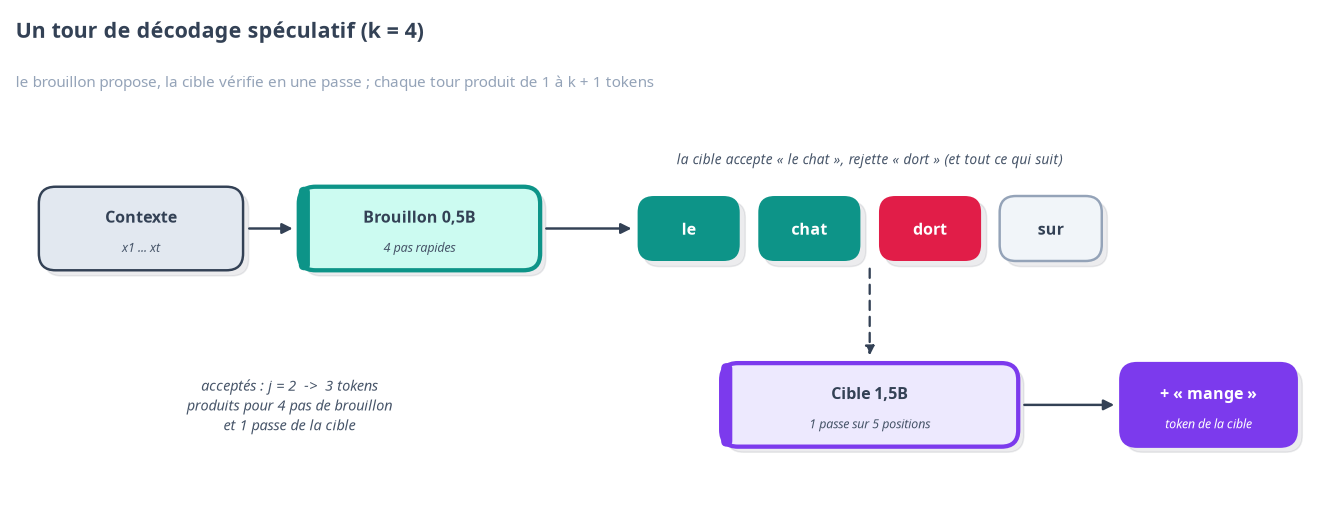

In [11]:
d = Diagram(14, 4.4, title="Un tour de décodage spéculatif (k = 4)",
            subtitle="le brouillon propose, la cible vérifie en une passe ; chaque tour produit de 1 à k + 1 tokens")
d.box("ctx", 1.4, 3.0, "Contexte", sub="x1 ... xt", color=SLATE, w=2.2)
d.box("dr", 4.4, 3.0, "Brouillon 0,5B", sub="4 pas rapides", color=TEAL, kind="model", w=2.6)
toks = [("p1", "le", TEAL), ("p2", "chat", TEAL), ("p3", "dort", ROSE), ("p4", "sur", GRAY)]
for i, (k, t, c) in enumerate(toks):
    d.box(k, 7.3 + i * 1.3, 3.0, t, color=c, w=1.1, h=0.7, kind="tag" if c != GRAY else "box")
d.note(9.25, 3.75, "la cible accepte « le chat », rejette « dort » (et tout ce qui suit)", fontsize=9)
d.box("tg", 9.25, 1.1, "Cible 1,5B", sub="1 passe sur 5 positions", color=VIOLET, kind="model", w=3.2)
d.box("out", 12.9, 1.1, "+ « mange »", sub="token de la cible", color=VIOLET, w=1.9, filled=True)
d.arrow("ctx", "dr"); d.arrow("dr", "p1")
d.line([(9.25, 2.6), (9.25, 1.6)], color=SLATE, style="dashed", lw=1.5)
d.arrow("tg", "out")
d.note(3.0, 1.1, "acceptés : j = 2  ->  3 tokens\nproduits pour 4 pas de brouillon\net 1 passe de la cible", fontsize=9.5)
d.show()

**Analyse.** Supposons que chaque token proposé soit accepté avec probabilité $\alpha$,
indépendamment (tant que les précédents l'ont été). Le nombre de tokens produits par tour
vaut $1 + j$, avec $j$ le nombre d'acceptations, d'où
$$\mathbb{E}[\text{tokens par tour}] = \sum_{i=0}^{k} \alpha^i = \frac{1 - \alpha^{k+1}}{1 - \alpha}.$$
Si un pas du brouillon coûte $c$ fois un pas de la cible et la vérification environ un pas
de la cible, un tour coûte $k c + 1$, et l'accélération attendue est
$$S(\alpha, k, c) = \frac{1 - \alpha^{k+1}}{(1 - \alpha)(k c + 1)}.$$
Elle croît avec $\alpha$, décroît avec $c$, et admet un $k$ optimal : trop court, on
n'exploite pas les bonnes séries ; trop long, on paie des propositions qui seront jetées.

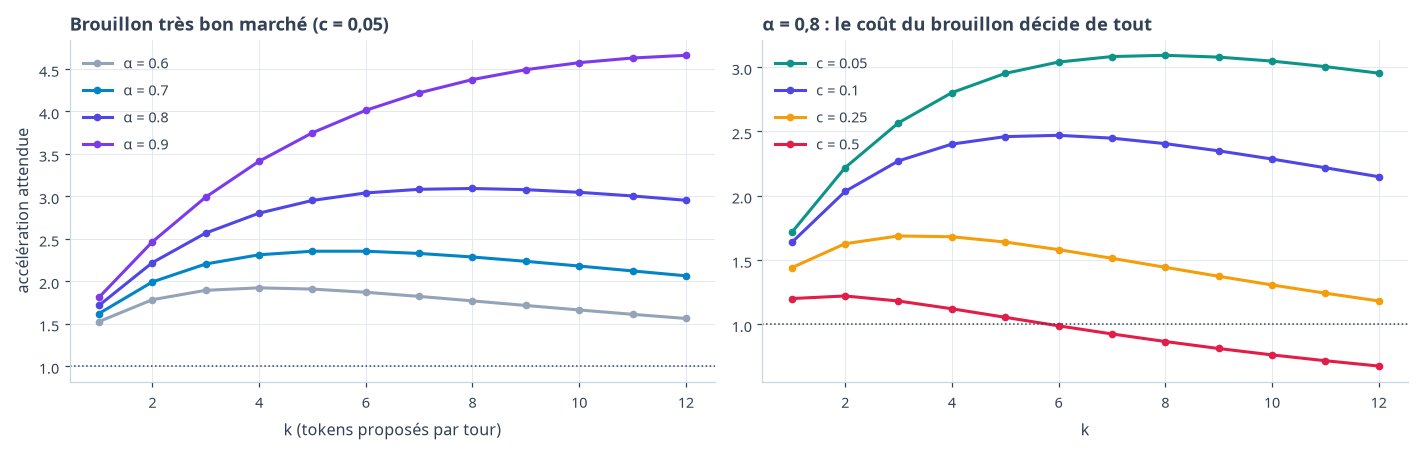

In [12]:
ks = np.arange(1, 13)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for a, c_ in zip([0.6, 0.7, 0.8, 0.9], [GRAY, SKY, INDIGO, VIOLET]):
    ax.plot(ks, inf.speculative_speedup(a, ks, 0.05), "o-", color=c_, ms=4, label=f"α = {a}")
ax.axhline(1, color=SLATE, lw=1, ls=":")
ax.set_xlabel("k (tokens proposés par tour)"); ax.set_ylabel("accélération attendue")
ax.set_title("Brouillon très bon marché (c = 0,05)"); ax.legend()
ax = axes[1]
for c_, col in zip([0.05, 0.1, 0.25, 0.5], [TEAL, INDIGO, AMBER, ROSE]):
    ax.plot(ks, inf.speculative_speedup(0.8, ks, c_), "o-", color=col, ms=4, label=f"c = {c_}")
ax.axhline(1, color=SLATE, lw=1, ls=":")
ax.set_xlabel("k"); ax.set_title("α = 0,8 : le coût du brouillon décide de tout"); ax.legend()
plt.tight_layout(); plt.show()

**Expérience.** Brouillon Qwen2.5-0.5B-Instruct, cible Qwen2.5-1.5B-Instruct (même
tokenizer). On mesure d'abord $c$, le rapport des durées d'un pas de decode, puis on
génère 96 tokens pour quatre prompts variés, en glouton classique et en spéculatif pour
plusieurs $k$ (médiane de 2 répétitions).

In [13]:
c_draft = (inf.retry_oom(inf.decode_step_time, drf, context=128)["median"]
           / inf.retry_oom(inf.decode_step_time, tgt, context=128)["median"])
print(f"coût relatif d'un pas du brouillon : c = {c_draft:.2f}")

prompts = {"code": "Write a Python function that returns the n-th Fibonacci number, with a docstring.",
           "liste": "List the eight planets of the solar system in order, one per line, with one fact each.",
           "explication": "Explique en quelques phrases ce qu'est le cache KV d'un modèle de langage.",
           "traduction": "Translate into French: The weather is nice today, so we will walk to the old harbour."}
stop = inf.eos_ids(tok_t)


def run_spec():
    """Glouton et spéculatif sont exécutés en alternance (le GPU est partagé : les deux subissent
    la même charge) ; accélération = médiane des temps par token du glouton / du spéculatif."""
    rows, texts = [], {}
    for name, p in prompts.items():
        ids_p = llm._chat_inputs(tok_t, p)["input_ids"][0].tolist()
        inf.greedy_generate(tgt, ids_p, 8)
        for k in [1, 2, 3, 4, 6]:
            base, runs = [], []
            for _ in range(2):
                base.append(inf.greedy_generate(tgt, ids_p, 96, stop=stop))
                runs.append(inf.assisted_generate(tgt, ids_p, inf.DraftModelProposer(drf), k=k, max_new_tokens=96,
                                                  stop=stop))
            texts[name] = tok_t.decode(base[0].tokens, skip_special_tokens=True)
            r = runs[0]
            rows.append(dict(prompt=name, k=k, alpha=inf.estimate_alpha(r.rounds, r.proposed),
                             tokens_par_tour=len(r.tokens) / r.forwards,
                             speedup=np.median([b.seconds / len(b.tokens) for b in base])
                             / np.median([x.seconds / len(x.tokens) for x in runs]),
                             identique=r.tokens == base[0].tokens))
    return pd.DataFrame(rows), texts


spec, texts = inf.retry_oom(run_spec)
print("sortie de la cible (code, début) :", texts["code"][:160].replace("\n", " | "))
spec.pivot_table(index="prompt", columns="k", values=["alpha", "speedup"]).style.format("{:.2f}")

coût relatif d'un pas du brouillon : c = 0.49


sortie de la cible (code, début) : Certainly! Below is a Python function that calculates the n-th Fibonacci number using an iterative approach. The function includes a docstring explaining its pu


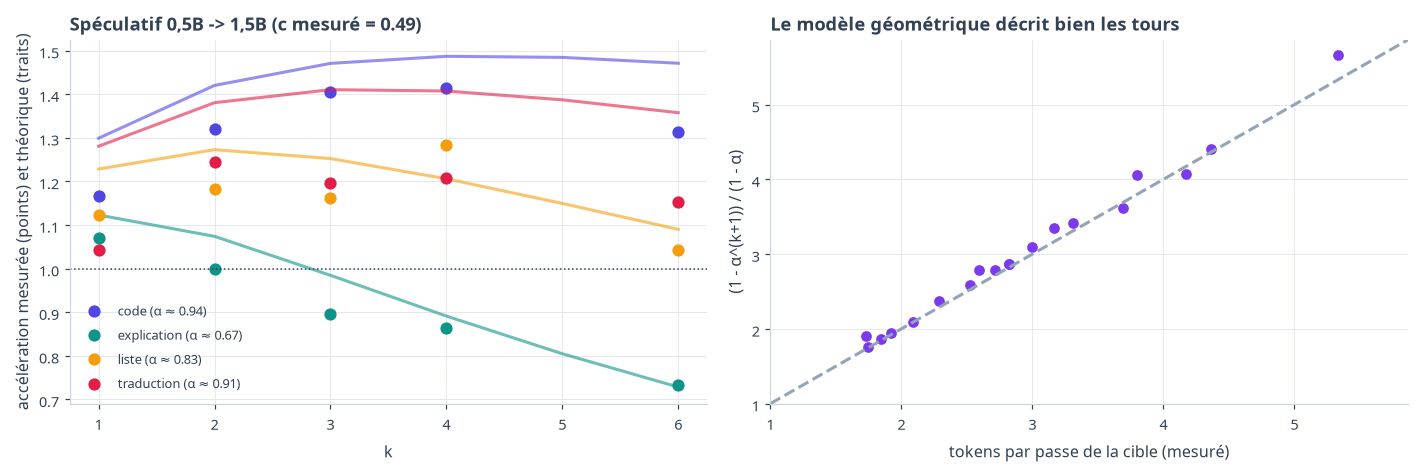

sorties identiques au glouton de la cible : 90% des essais


In [14]:
alpha_by_prompt = spec.groupby("prompt")["alpha"].median()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
for (name, g), c_ in zip(spec.groupby("prompt"), [INDIGO, TEAL, AMBER, ROSE]):
    a = alpha_by_prompt[name]
    ax.plot(g["k"], g["speedup"], "o", color=c_, ms=7, label=f"{name} (α ≈ {a:.2f})")
    ax.plot(ks[:6], inf.speculative_speedup(a, ks[:6], c_draft), "-", color=c_, alpha=0.6)
ax.axhline(1, color=SLATE, lw=1, ls=":")
ax.set_xlabel("k"); ax.set_ylabel("accélération mesurée (points) et théorique (traits)")
ax.set_title(f"Spéculatif 0,5B -> 1,5B (c mesuré = {c_draft:.2f})"); ax.legend(fontsize=8.5)
ax = axes[1]
ax.plot(spec["tokens_par_tour"], [float(inf.expected_tokens_per_round(a, k)) for a, k in zip(spec["alpha"], spec["k"])],
        "o", color=VIOLET)
lim = [1, spec["tokens_par_tour"].max() * 1.1]
ax.plot(lim, lim, color=GRAY, ls="--"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("tokens par passe de la cible (mesuré)"); ax.set_ylabel("(1 - α^(k+1)) / (1 - α)")
ax.set_title("Le modèle géométrique décrit bien les tours")
plt.tight_layout(); plt.show()
print(f"sorties identiques au glouton de la cible : {spec['identique'].mean():.0%} des essais")

Lecture des résultats :

- le **taux d'acceptation** est élevé (souvent 0,7 à 0,95) et dépend du **domaine** : les
  textes très contraints (liste, code) s'acceptent mieux que la prose libre, comme le note
  le livre ;
- le nombre de tokens par passe de la cible suit bien la formule géométrique ;
- l'**accélération**, en revanche, est modeste : sur ce GPU, le brouillon n'est pas 10 fois
  moins cher que la cible mais seulement deux à trois fois ($c$ mesuré ci-dessus). Pour des
  modèles aussi petits, un pas de decode est dominé par le surcoût fixe (lancement des
  noyaux, Python), pas par la lecture des poids ; 0,5B et 1,5B paient donc presque le même
  prix. La formule théorique, avec le $c$ mesuré, prédit correctement cet ordre de
  grandeur. Avec un écart de taille réaliste (le livre cite un brouillon de 4 milliards de
  paramètres pour Chinchilla-70B, 8 fois plus rapide par token), $c$ tombe sous 0,15 et
  l'accélération dépasse 2 ;
- les sorties sont identiques à celles de la cible dans la grande majorité des essais ; un
  écart occasionnel vient de l'arithmétique bf16 (vérifier 5 tokens en une passe ne
  produit pas exactement les mêmes arrondis que 5 passes d'un token), pas de l'algorithme.

> **À retenir.** Accélération $= \frac{1 - \alpha^{k+1}}{(1 - \alpha)(kc + 1)}$ : il faut à
> la fois un brouillon **fidèle** ($\alpha$ grand, même tokenizer) et **bon marché**
> ($c$ petit). Sans changer la qualité, la technique est intégrée à vLLM, TensorRT-LLM et
> llama.cpp.